# DES Y3: what does the three-point vector add to an IA forecast?

Read the numbered NLA and TATT examples, evaluate their Cobaya theory blocks,
and call the shared CosmoLike Fisher functions. Each calculation is visible in
this notebook; there is no separate forecast driver or result-management class.
CAMB and the absolute bispectrum are supplied by the YAML theory blocks.

The comparisons address the IA sign response, derivative degeneracy, marginalized
errors and fixed-dark-energy amplitude constraints discussed by Gomes et al.
([methods](https://arxiv.org/abs/2503.03964),
[TATT model](https://arxiv.org/abs/2601.09133)). They are local forecasts, not
reproductions of the published posterior. The numbered examples use a fixed
simulation covariance, demonstration source clipping and declared finite-triangle
projection settings. Their exact estimator match and small-scale modeling still
require separate tests. IA uses CosmoLike's normalization and pivot.

**Execution:** the cells below perform real calculations when run. No forecasts
were rerun as part of the source refactor; outputs are intentionally empty.

These examples use the unmasked, uncompressed row order of numbered examples 1
and 2. A different dataset mask or compression requires matching row labels
before using the two-/three-point split shown here.

The companion [teaching note](intrinsic_alignments.pdf) derives the cross-covariance,
Fisher and amplitude calculations used below, with small numerical examples.

For the individual gravitational and intrinsic-shape contributions, read the
[IA component example](../../EXAMPLE_IA_COMPONENTS.ipynb). Its operator
decomposition answers a different question from marginalizing parameter errors.


## 1. Load the same numerical environment as the numbered example

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
# BLAS must not start another worker team inside the native OpenMP calculation.
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "4"

from copy import deepcopy
from pathlib import Path
import sys
import importlib
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from scipy.linalg import solve_triangular
from cobaya.model import get_model
from cobaya.yaml import yaml_load_file, yaml_dump_file

project = Path.cwd().resolve()
while not (project / "EXAMPLE_EVALUATE3.yaml").exists():
    if project == project.parent:
        raise FileNotFoundError("Open this notebook from the DES project directory.")
    project = project.parent
cocoa = project.parents[1]
sys.path.insert(0, str(project / "interface"))
sys.path.insert(0, str(cocoa / "external_modules/code/cosmolike_core"))
import cosmolike_des_3pcf_interface as ci
import cosmolike_notebook_utils.fisher as cnu

# Numbered Cocoa YAMLs resolve package and dataset paths from the Cocoa directory.
os.chdir(cocoa)

In [2]:
# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'

In [3]:
# CAMB's derived sigma8 at every evaluated point, keyed by the point.
# As_1e9 is sampled and sigma8 is derived, so S8 = sigma8 (Omega_m/0.3)^(1/2)
# depends on every cosmological parameter. get_s8 differentiates it with the
# same stencils as the data vector, so it needs no CAMB evaluation of its own.
sigma8_values = {}


def get_dv(parameters):
    """Evaluate the current numbered Cobaya model at a physical parameter point.

    Cobaya runs its declared theory blocks before the DES likelihood. The
    likelihood retains the full mean it evaluated; the native selector applies
    its data mask and compression. A Fisher displacement must reach that same
    prediction, not another CAMB or bispectrum preparation route.

    Arguments:
      parameters = dictionary of sampled physical parameters for the current model.
    Returns:
      Owned one-dimensional selected data vector, in the covariance's row order.
    Raises:
      RuntimeError if the likelihood evaluation is not finite.
    Side effects:
      Updates the current model and the process-global native cosmology,
      and records CAMB's derived sigma8 at this point in sigma8_values.
    """
    loglikes, derived = model.loglikes(
        params_values=parameters,
        return_derived=True,
        as_dict=True,
        cached=False,
    )
    if not np.all(np.isfinite(list(loglikes.values()))):
        raise RuntimeError("A Fisher point has nonfinite likelihood; inspect that point.")
    sigma8_values[tuple(sorted(parameters.items()))] = derived["sigma8"]
    return np.array(
        object=ci.select_joint_data_vector(prediction=likelihood.last_datavector),
        dtype=np.float64,
        copy=True,
    )


def get_s8(parameters):
    """Return S8 = sigma8 (Omega_m/0.3)^(1/2) at a point, as a one-entry vector.

    sigma8 is CAMB's derived value that get_dv recorded at the same point.
    Passing get_s8 to cnu.differentiate with the data-vector steps gives the
    gradient dS8/dp of every parameter; the Omega_m entry includes both the
    explicit square root and the change of sigma8.

    Arguments:
      parameters = dictionary of sampled physical parameters, with omegam.
    Returns:
      One-dimensional array holding S8.
    Side effects:
      Evaluates the model through get_dv only if the point is not recorded.
    """
    key = tuple(sorted(parameters.items()))
    if key not in sigma8_values:
        get_dv(parameters=parameters)
    return np.array([sigma8_values[key] * np.sqrt(parameters["omegam"] / 0.3)])

## 2. Compare IA signs before differentiating

Use the TATT example for every mean in this section, so sources, covariance,
cosmology, source shifts and numerical grids remain fixed. Set the quadratic
amplitude and density weighting to zero for NLA; also set the linear amplitude
to zero for the no-IA reference. The redshift exponents retain the YAML values.
The two nonzero amplitude choices illustrate the sign changes discussed in
Fig. 9 of the TATT paper (arXiv:2601.09133); they do not silently replace
the example's fiducial point.

In [4]:
info = yaml_load_file(str(project / "EXAMPLE_EVALUATE4.yaml"))
fiducial = dict(info["sampler"]["evaluate"]["override"])
info.pop("sampler")
info.pop("output", None)
info["likelihood"]["des_3pcf.joint_shear"]["omp_threads"] = 4

model = get_model(info_or_yaml_or_file=info)
likelihood = model.likelihood["des_3pcf.joint_shear"]
# Numbered examples 1 and 2 retain all rows, without compression.
covariance = np.array(object=ci.get_joint_covariance(), copy=True)
row_kind = likelihood.rows.kind.copy()
row_bins = likelihood.rows.bins.copy()
row_angles = likelihood.rows.angles.copy()
row_labels = likelihood.rows.labels.copy()

# Each tuple is (A1, A2, density-weighting amplitude).
choices = {
    "no_ia": (0.0, 0.0, 0.0),
    "nla_negative": (-0.2, 0.0, 0.0),
    "nla_positive": (0.2, 0.0, 0.0),
    "tatt_negative": (-0.2, 0.4, fiducial["DES_BTA_1"]),
    "tatt_positive": (0.2, -0.4, fiducial["DES_BTA_1"]),
}
sign_means = {}
try:
    for name, amplitudes in choices.items():
        point = dict(fiducial)
        point["DES_A1_1"] = amplitudes[0]
        point["DES_A2_1"] = amplitudes[1]
        point["DES_BTA_1"] = amplitudes[2]
        sign_means[name] = get_dv(parameters=point)
finally:
    # CosmoLike owns process-global state: close this model before the next one.
    model.close()

[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


[des_3pcf.joint_shear] Average evaluation time for des_3pcf.joint_shear: 8.87742 s  (4 evaluations)


[camb.transfers] Average evaluation time for camb.transfers: 0.475634 s  (4 evaluations)


[camb] Average evaluation time for camb: 0.369771 s  (4 evaluations)


[bihalofit] Average evaluation time for bihalofit: 0.0174061 s  (4 evaluations)


### Show the changes in measurement-error units

A curve displays the change from no IA divided by each row's standard deviation.
A value of one is one marginal row error. The rows remain correlated: summing
these plotted values squared would not give the likelihood distance. The next
cell computes that distance using the complete covariance, including the
cross block between two- and three-point measurements.

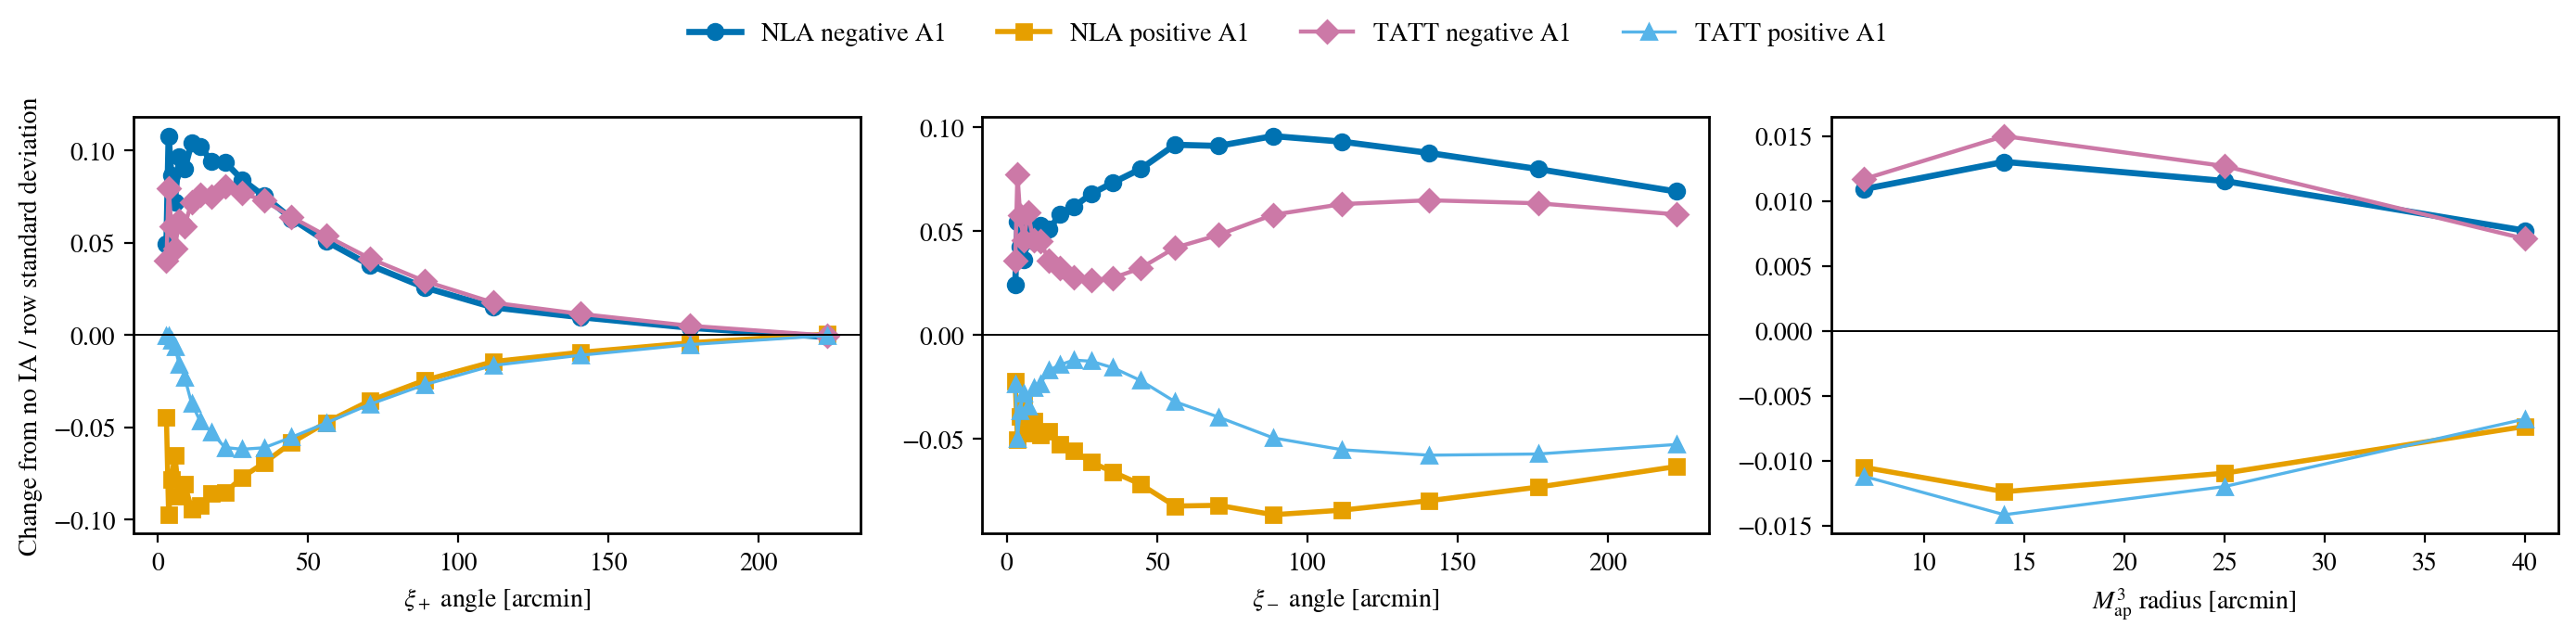

In [5]:
# Display one source auto-bin, retaining all rows for subsequent matrix fits.
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(14, 3.5))
colors = ["#0072B2", "#E69F00", "#CC79A7", "#56B4E9"]
markers = ["o", "s", "D", "^"]
labels = ["NLA negative A1", "NLA positive A1", "TATT negative A1", "TATT positive A1"]
case_names = ["nla_negative", "nla_positive", "tatt_negative", "tatt_positive"]
for panel, kind in enumerate(("xip", "xim", "map3")):
    selected = (row_kind == kind) & (row_bins[:, 0] == 3) & (row_bins[:, 1] == 3)
    if kind == "map3":
        selected &= row_bins[:, 2] == 3
        angle_column = 0
    else:
        angle_column = 2
    angle = row_angles[selected, angle_column] * 180.0 * 60.0 / np.pi
    sigma = np.sqrt(np.diag(covariance))[selected]
    for index, name in enumerate(case_names):
        difference = sign_means[name][selected] - sign_means["no_ia"][selected]
        axes[panel].plot(
            angle,
            difference / sigma,
            color=colors[index],
            marker=markers[index],
            linewidth=2.4 - 0.4 * index,
            label=labels[index],
        )
    axes[panel].axhline(y=0, color="black", linewidth=0.7)
    angle_labels = [r"$\xi_+$ angle [arcmin]", r"$\xi_-$ angle [arcmin]",
                    r"$M_{\mathrm{ap}}^3$ radius [arcmin]"]
    axes[panel].set_xlabel(angle_labels[panel])
axes[0].set_ylabel("Change from no IA / row standard deviation")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles=handles, labels=labels, loc="upper center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.87))
plt.show()

In [6]:
for ia_model in ("nla", "tatt"):
    # A single contrast column measures a finite fixed-model distance. It is
    # not a fitted amplitude or a posterior detection significance.
    delta = sign_means[ia_model + "_positive"] - sign_means[ia_model + "_negative"]
    distance = cnu.compare_information(
        derivatives=delta[:, None],
        names=["sign_contrast"],
        kind=row_kind,
        covariance=covariance,
    )
    print(ia_model, "joint / two-point / new three-point chi2:")
    print(
        distance["fisher_joint_likelihood"][0, 0],
        distance["fisher_two_point_likelihood"][0, 0],
        distance["fisher_conditional_three_point"][0, 0],
    )

nla joint / two-point / new three-point chi2:
15.06261989689694 7.82703503233021 7.235584864566734
tatt joint / two-point / new three-point chi2:
7.482030737014473 5.121695776331396 2.360334960683076


## 3. Construct the Fisher matrices in the notebook

For a fixed covariance, the derivative matrix $D$ gives

$$F_\mathrm{likelihood}=D^T C^{-1}D.$$

Each column varies one physical parameter; all the other values stay at the
YAML fiducial. We add Gaussian calibration priors once, after constructing the
likelihood information. The notebook opens $w_0,w_a$ to test dark-energy
marginalization; the numbered inference examples otherwise hold them fixed.

The shared routine evaluates five-point centered derivatives at absolute steps
$h$ and $h/2$. Compare their *covariance-weighted* differences, since tiny Map3
values can carry substantial information. The physical source, IA and covariance
assumptions are the same across both step sizes.

In [7]:
# These are absolute physical displacements, not percentages of a fiducial.
# Small nuisance steps and larger dark-energy steps therefore have explicit units.
steps = {
    "omegam": 0.003,
    "As_1e9": 0.024,
    "omegab": 0.0005,
    "H0": 0.5,
    "ns": 0.005,
    "DES_A1_1": 0.01,
    "DES_A1_2": 0.03,
    "DES_M1": 0.001,
    "DES_M2": 0.001,
    "DES_M3": 0.001,
    "DES_M4": 0.001,
    "DES_DZ_S1": 0.001,
    "DES_DZ_S2": 0.001,
    "DES_DZ_S3": 0.001,
    "DES_DZ_S4": 0.001,
    "w": 0.02,
    "wa": 0.04,
}
# Gaussian source-calibration widths enter once. Flat prior limits do not
# supply Gaussian information; their posterior truncation is absent here.
priors = {
    "DES_M1": 0.0091,
    "DES_M2": 0.0078,
    "DES_M3": 0.0076,
    "DES_M4": 0.0076,
    "DES_DZ_S1": 0.018,
    "DES_DZ_S2": 0.015,
    "DES_DZ_S3": 0.011,
    "DES_DZ_S4": 0.017,
}

In [8]:
forecasts = {}
for ia_model, filename in (("nla", "EXAMPLE_EVALUATE3.yaml"),
                           ("tatt", "EXAMPLE_EVALUATE4.yaml")):
    info = yaml_load_file(str(project / filename))
    fiducial = dict(info["sampler"]["evaluate"]["override"])
    info.pop("sampler")
    info.pop("output", None)
    info["likelihood"]["des_3pcf.joint_shear"]["omp_threads"] = 4
    # Unlike the numbered inference example, this diagnostic varies dark energy.
    # Removing the fixed values lets Cobaya pass the two stencil coordinates to CAMB.
    info["params"]["w"] = {
        "prior": {"min": -2.0, "max": -0.3},
        "ref": -1.0,
    }
    info["params"]["wa"] = {
        "prior": {"min": -2.0, "max": 2.0},
        "ref": 0.0,
    }
    fiducial["w"] = -1.0
    fiducial["wa"] = 0.0
    case_steps = dict(steps)
    if ia_model == "tatt":
        case_steps["DES_A2_1"] = 0.02
        case_steps["DES_A2_2"] = 0.03
        case_steps["DES_BTA_1"] = 0.02
    model = get_model(info_or_yaml_or_file=info)
    likelihood = model.likelihood["des_3pcf.joint_shear"]
    sigma8_values.clear()
    try:
        covariance = np.array(object=ci.get_joint_covariance(), copy=True)
        names, center, dh, dh2 = cnu.differentiate(
            predict=get_dv,
            parameters=fiducial,
            steps=case_steps,
        )
        # dS8/dp from CAMB's sigma8 at the stencil points just evaluated.
        s8_names, _, _, s8_h2 = cnu.differentiate(
            predict=get_s8,
            parameters=fiducial,
            steps=case_steps,
        )
        assert s8_names == names
        information = cnu.compare_information(
            derivatives=dh2,
            names=names,
            kind=likelihood.rows.kind,
            covariance=covariance,
            priors=priors,
        )
        errors, status = cnu.marginalized_errors(comparison=information, names=names)
        factor = np.linalg.cholesky(covariance)
        whitened_change = solve_triangular(a=factor, b=dh2-dh, lower=True)
        whitened_ref = solve_triangular(a=factor, b=dh2, lower=True)
        change = np.linalg.norm(whitened_change, axis=0)
        change /= np.linalg.norm(whitened_ref, axis=0)
        print(ia_model, status)
        for name, value in zip(names, change):
            print(name, "derivative change [%]:", 100.0 * value)
        forecasts[ia_model] = {
            "names": names,
            "fiducial": dict(fiducial),
            "s8_gradient": s8_h2[0],
            "mean": center,
            "derivatives_h": dh,
            "derivatives_h2": dh2,
            "covariance": covariance,
            "row_kind": likelihood.rows.kind.copy(),
            "row_bins": likelihood.rows.bins.copy(),
            "row_angles": likelihood.rows.angles.copy(),
            "information": information,
            "errors": errors,
            "status": status,
        }
        directory = project / "chains/fisher_ia"
        directory.mkdir(parents=True, exist_ok=True)
        yaml_dump_file(str(directory / (ia_model + ".yaml")), info, error_if_exists=False)
        np.savez(
            file=directory / (ia_model + ".npz"),
            names=np.asarray(names),
            steps=np.asarray(list(case_steps.values())),
            mean=center,
            covariance=covariance,
            derivatives_h=dh,
            derivatives_h2=dh2,
            fisher_joint=information["fisher_joint"],
            fisher_two_point=information["fisher_two_point"],
            s8_gradient=s8_h2[0],
        )
    finally:
        model.close()

[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


nla {'two_point': 'resolved', 'joint': 'resolved'}
omegam derivative change [%]: 0.07358015125847987
As_1e9 derivative change [%]: 0.003470342494502808
omegab derivative change [%]: 0.005393454739957917
H0 derivative change [%]: 0.058462914881966116
ns derivative change [%]: 0.006908643436416213
DES_A1_1 derivative change [%]: 7.872780609155925e-10
DES_A1_2 derivative change [%]: 8.146828872275534e-07
DES_M1 derivative change [%]: 2.6779775966214974e-11
DES_M2 derivative change [%]: 2.517456504039068e-11
DES_M3 derivative change [%]: 2.2277387056303716e-11
DES_M4 derivative change [%]: 2.3110789733637463e-11
DES_DZ_S1 derivative change [%]: 0.01893768965122446
DES_DZ_S2 derivative change [%]: 0.027299994151533037
DES_DZ_S3 derivative change [%]: 0.019086350397798373
DES_DZ_S4 derivative change [%]: 0.05864192367130211
w derivative change [%]: 0.007618390438470032
wa derivative change [%]: 0.008836323666157869
[des_3pcf.joint_shear] Average evaluation time for des_3pcf.joint_shear: 4.88

[camb.transfers] Average evaluation time for camb.transfers: 0.576232 s  (136 evaluations)


[camb] Average evaluation time for camb: 0.284554 s  (136 evaluations)


[bihalofit] Average evaluation time for bihalofit: 5.59225 s  (136 evaluations)


[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


tatt {'two_point': 'resolved', 'joint': 'resolved'}
omegam derivative change [%]: 0.07577776387420053
As_1e9 derivative change [%]: 0.0035676697532707365
omegab derivative change [%]: 0.005633458204115453
H0 derivative change [%]: 0.06051496822694432
ns derivative change [%]: 0.0073234952383149435
DES_A1_1 derivative change [%]: 5.483066146627731e-10
DES_A1_2 derivative change [%]: 5.220520662956964e-07
DES_M1 derivative change [%]: 3.138797896057542e-11
DES_M2 derivative change [%]: 2.3443550076203897e-11
DES_M3 derivative change [%]: 2.1082069455785027e-11
DES_M4 derivative change [%]: 2.1813719998203065e-11
DES_DZ_S1 derivative change [%]: 0.023442571082638697
DES_DZ_S2 derivative change [%]: 0.027782317469024275
DES_DZ_S3 derivative change [%]: 0.014716959813822568
DES_DZ_S4 derivative change [%]: 0.05594016688189987
w derivative change [%]: 0.007759114588197466
wa derivative change [%]: 0.009147983796128798
DES_A2_1 derivative change [%]: 7.686530629310059e-10
DES_A2_2 derivative 

[camb.transfers] Average evaluation time for camb.transfers: 0.560213 s  (160 evaluations)


[camb] Average evaluation time for camb: 0.283531 s  (160 evaluations)


[bihalofit] Average evaluation time for bihalofit: 5.07119 s  (160 evaluations)


## 4. Read the normalized derivative shapes

Take $\Delta p$ times a derivative column. It has the same units as a mean
change and can be compared with a second column. The shared template plot fits
the best multiple of the second response using $C^{-1}$, first with two-point
rows and then with the joint vector. The remaining response shows information
that this one competing parameter cannot imitate. This is a two-column
comparison, not marginalization over every cosmological and nuisance parameter.

When adding Map3 makes two responses more parallel, report that result. Added
data cannot decrease the exact Fisher information for a fixed model/covariance,
but the angle between two response columns need not increase.

nla two_point signed response cosine: -0.748025902652955
Best fitted multiple: -0.2607206600087875
nla joint signed response cosine: -0.7954164777760376
Best fitted multiple: -0.24766882481977517


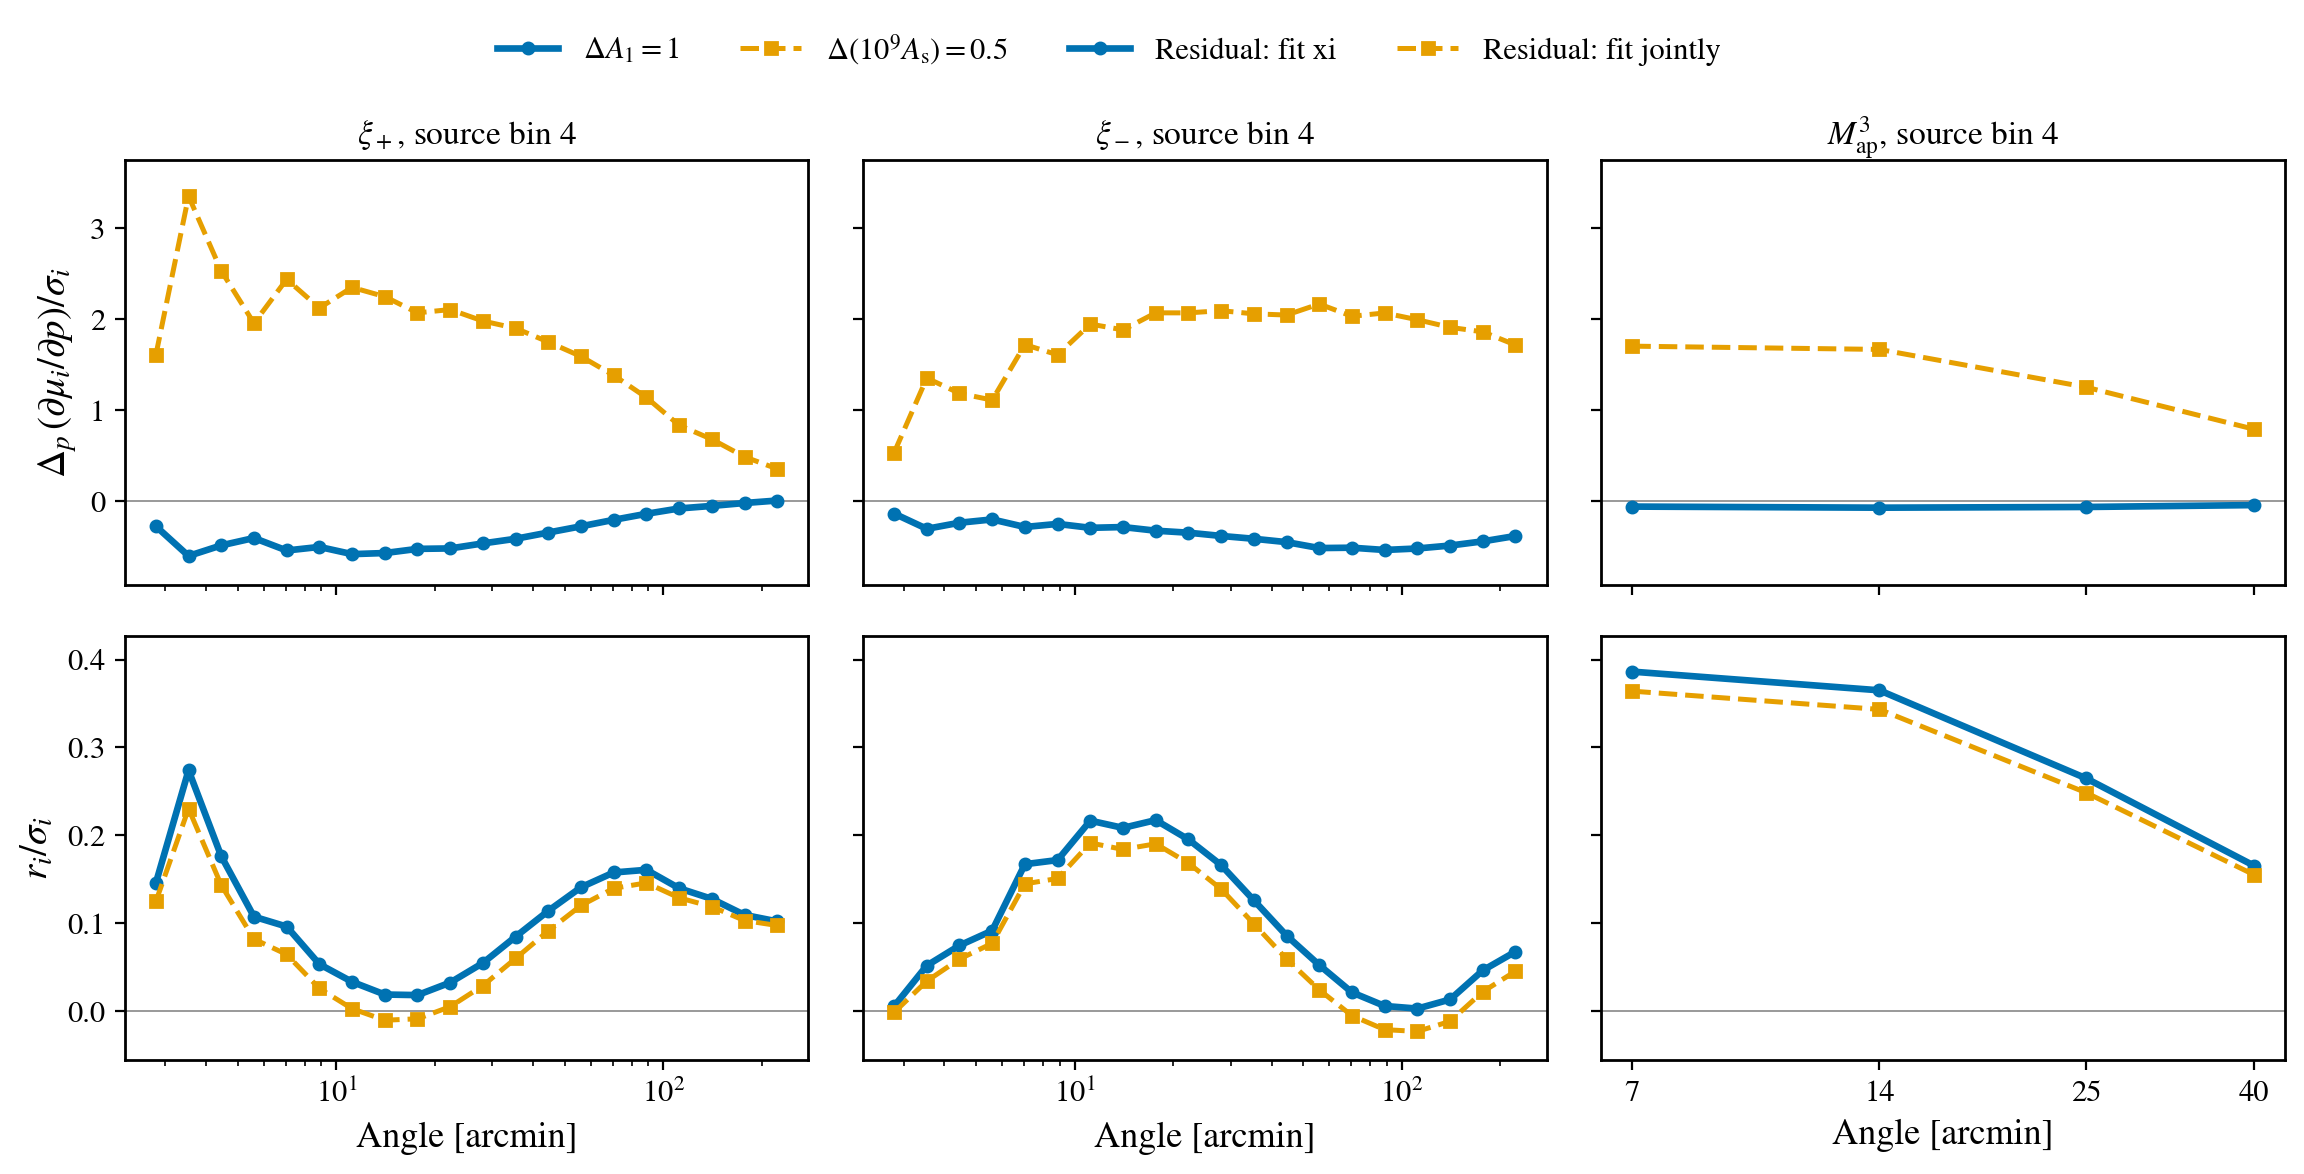

tatt two_point signed response cosine: 0.7351371668320884
Best fitted multiple: 2.0676559999402806
tatt joint signed response cosine: 0.800375120598232
Best fitted multiple: 2.2717863147308464


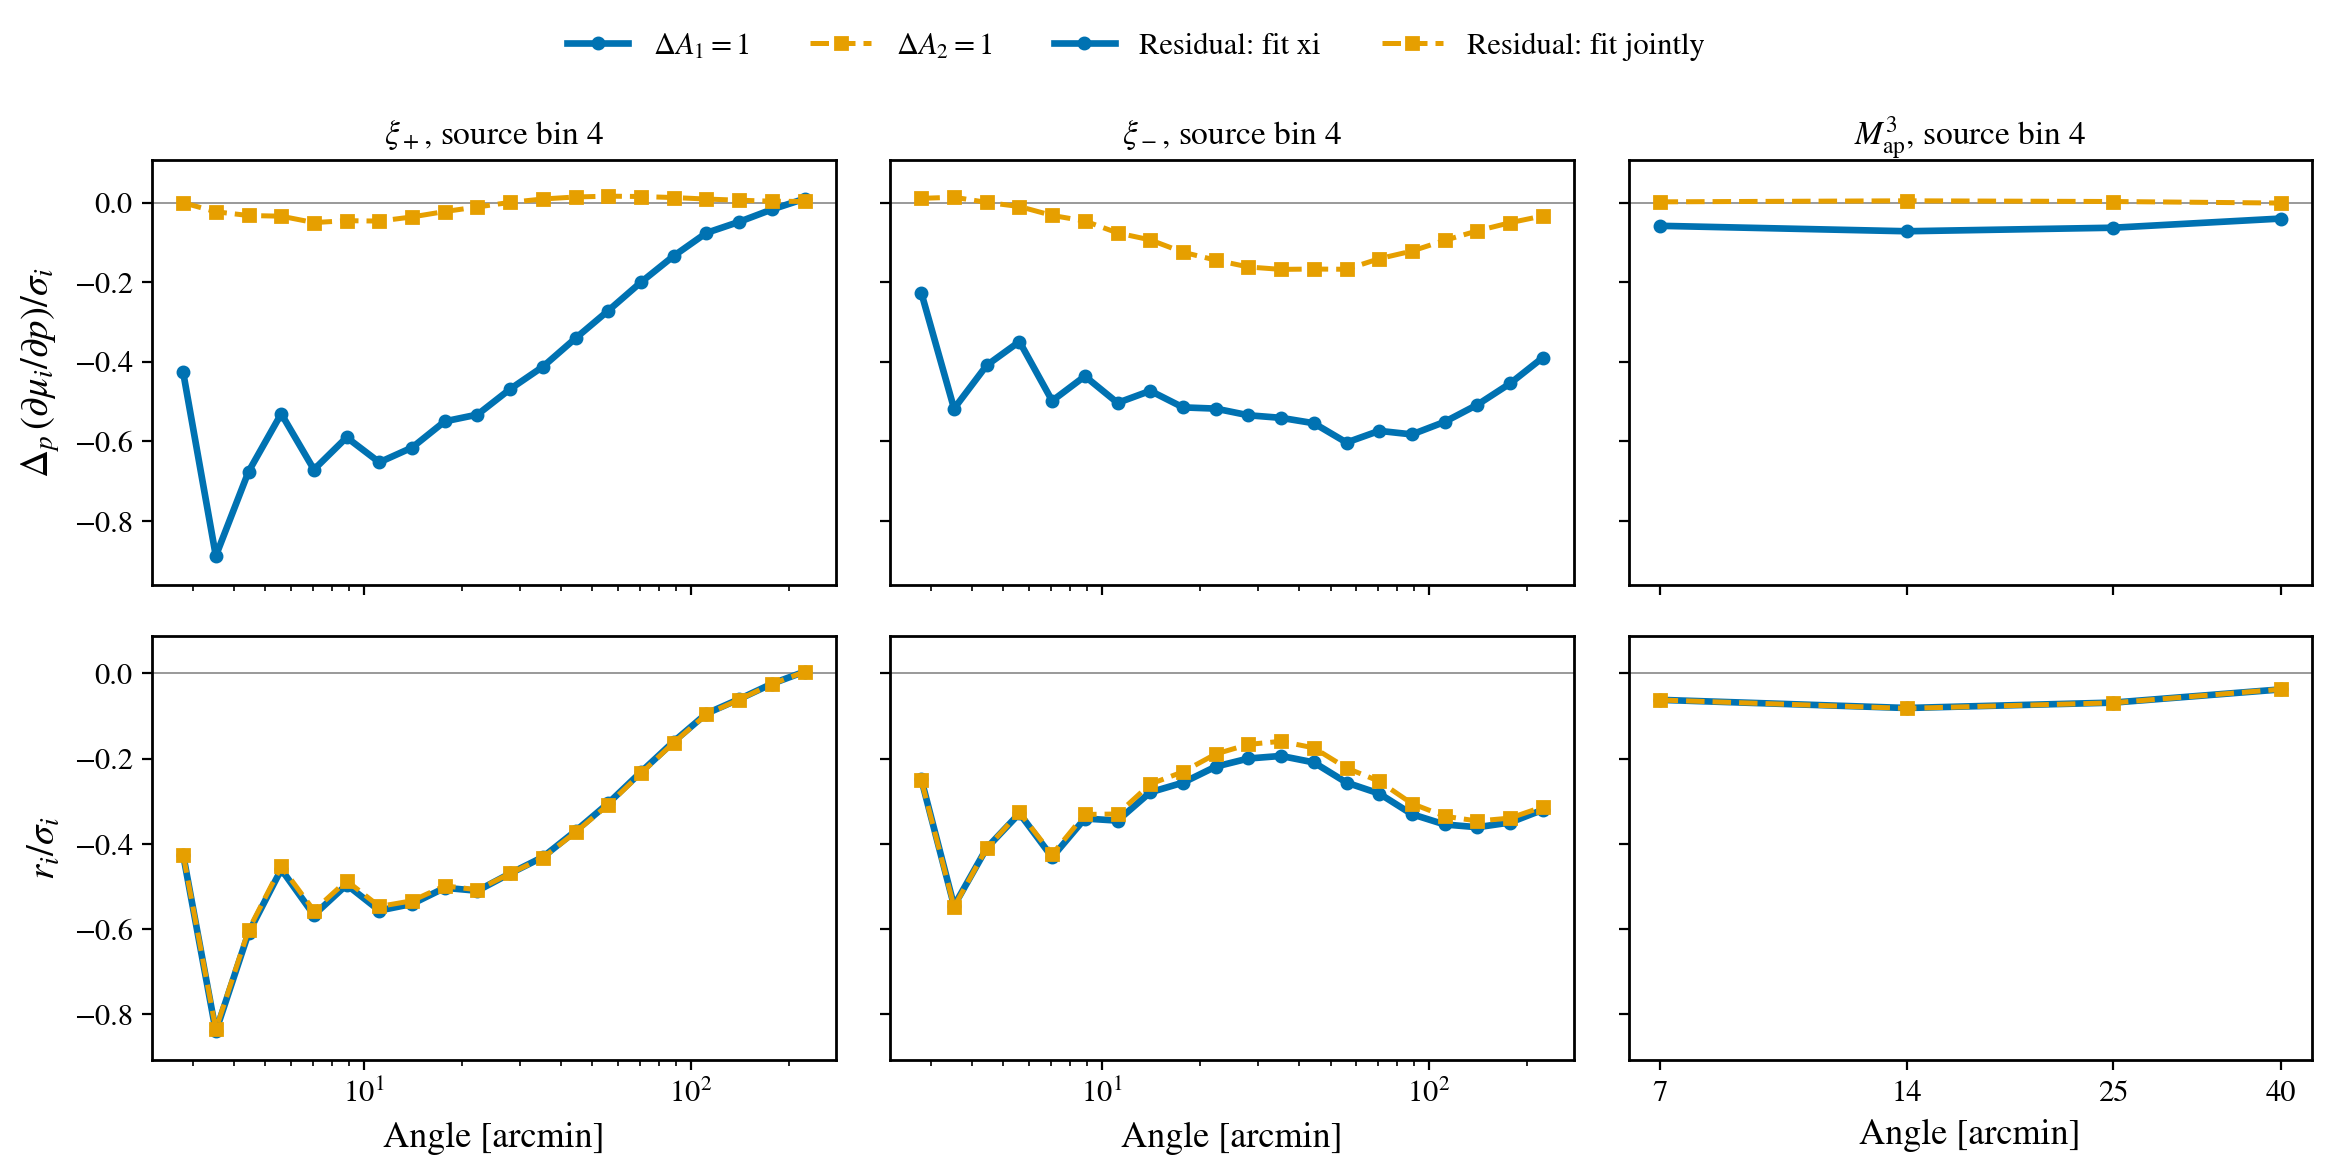

In [9]:
response_plots = importlib.import_module(
    name="cosmolike_notebook_utils.3pcf.derivative_templates",
)
for ia_model, mimic, mimic_scale in (("nla", "As_1e9", 0.5), ("tatt", "DES_A2_1", 1.0)):
    forecast = forecasts[ia_model]
    names = forecast["names"]
    derivatives = forecast["derivatives_h2"]
    shapes = response_plots.compare_templates(
        target=derivatives[:, names.index("DES_A1_1")],
        mimic=mimic_scale * derivatives[:, names.index(mimic)],
        covariance=forecast["covariance"],
        two_point=forecast["row_kind"] != "map3",
    )
    for probe in ("two_point", "joint"):
        print(ia_model, probe, "signed response cosine:", shapes[probe]["cosine"])
        print("Best fitted multiple:", shapes[probe]["coefficient"])
    panels = []
    for kind in ("xip", "xim", "map3"):
        bins = forecast["row_bins"]
        selected = (forecast["row_kind"] == kind) & (bins[:, 0] == 3) & (bins[:, 1] == 3)
        angle_column = 2
        if kind == "map3":
            selected &= bins[:, 2] == 3
            angle_column = 0
        indices = np.flatnonzero(selected)
        panels.append({
            "coordinate": forecast["row_angles"][indices, angle_column] * 10800.0 / np.pi,
            "templates": shapes["templates"][:, indices],
            "residuals": np.array([
                shapes["two_point"]["residual"][indices],
                shapes["joint"]["residual"][indices],
            ]),
            "title": {"xip": r"$\xi_+$", "xim": r"$\xi_-$",
                      "map3": r"$M_{\mathrm{ap}}^3$"}[kind] + ", source bin 4",
            "coordinate_label": "Angle [arcmin]",
        })
    response_plots.plot_derivative_templates(
        panels=panels,
        parameter_labels=[
            r"$\Delta A_1=1$",
            {"As_1e9": r"$\Delta(10^9A_\mathrm{s})=0.5$", "DES_A2_1": r"$\Delta A_2=1$"}[mimic],
        ],
        show=1,
    )

## 5. Marginalized errors, $S_8$ and fixed dark energy

The inverse of the **full** Fisher matrix marginalizes all its listed parameters.
To hold $w_0,w_a$ fixed, first remove their rows and columns from the Fisher
matrix, and only then invert. Removing them from an already inverted covariance
would instead retain their marginalization.

The derived amplitude $S_8=\sigma_8\sqrt{\Omega_m/0.3}$ has variance

$$\sigma^2(S_8)=g^T\operatorname{Cov}(p)g,$$

where $g_j=\partial S_8/\partial p_j$ for every listed parameter. The sampled
amplitude is $A_s$, so $\sigma_8$ is CAMB's derived value and depends on all the
cosmological parameters; the notebook differentiates CAMB's $S_8$ with the same
five-point stencils as the data vector. The off-diagonal covariance is part of
this expression. The calculation below reports both the full parameter space
and the fixed-dark-energy case, with the same prior counted once.

In [10]:
amplitude_forecasts = {}
for ia_model, forecast in forecasts.items():
    amplitude_forecasts[ia_model] = {}
    names = forecast["names"]
    print("IA model:", ia_model)
    if "sigma_joint" in forecast["errors"] and "sigma_two_point" in forecast["errors"]:
        for index, name in enumerate(names):
            if name in ("DES_A1_1", "DES_A1_2", "DES_A2_1", "DES_A2_2", "DES_BTA_1"):
                ratio = forecast["errors"]["sigma_joint"][index]
                ratio /= forecast["errors"]["sigma_two_point"][index]
                print(name, "joint / two-point marginalized error:", ratio)
    for fixed_dark_energy in (False, True):
        retained = []
        retained_names = []
        for index, name in enumerate(names):
            if fixed_dark_energy and name in ("w", "wa"):
                continue
            retained.append(index)
            retained_names.append(name)
        for probe in ("two_point", "joint"):
            fisher = forecast["information"]["fisher_" + probe]
            fisher = fisher[np.ix_(retained, retained)]
            # A failure here means the parameter set is unresolved. Do not
            # substitute a pseudoinverse and label it a marginalized forecast.
            try:
                parameter_cov = cnu.parameter_covariance(
                    fisher=fisher,
                    names=retained_names,
                )
            except ValueError as error:
                # A null dark-energy direction may disappear when it is fixed.
                # Report the unresolved case and still evaluate that distinct
                # experiment; never remove a retained nuisance to force a result.
                print(probe, "fixed dark energy:", fixed_dark_energy, str(error))
                continue
            # dS8/dp of the retained parameters, from CAMB's sigma8.
            gradient = forecast["s8_gradient"][retained]
            variance = gradient @ parameter_cov @ gradient
            print(probe, "fixed dark energy:", fixed_dark_energy)
            print("sigma(S8):", np.sqrt(variance))
            # Transform the already marginalized parameter covariance to
            # (Omega_m,S8), keeping their off-diagonal covariance.
            jacobian = np.zeros((2, len(retained)))
            jacobian[0, retained_names.index("omegam")] = 1.0
            jacobian[1] = gradient
            amplitude_covariance = jacobian @ parameter_cov @ jacobian.T
            amplitude_fom = 1.0 / np.sqrt(np.linalg.det(amplitude_covariance))
            print("FoM(Omega_m,S8):", amplitude_fom)

            # Retain the displayed quantities for comparisons without fitting
            # a second covariance or adding the same nuisance priors again.
            amplitude_forecasts[ia_model][fixed_dark_energy, probe] = {
                "names": list(retained_names),
                "parameter_covariance": parameter_cov,
                "sigma_s8": np.sqrt(variance),
                "omega_m_s8_fom": amplitude_fom,
            }


IA model: nla
DES_A1_1 joint / two-point marginalized error: 0.8953027599502658
DES_A1_2 joint / two-point marginalized error: 0.6062791209390144
two_point fixed dark energy: False
sigma(S8): 0.11542943988351975
FoM(Omega_m,S8): 150.31586844004056
joint fixed dark energy: False
sigma(S8): 0.06002674850187356
FoM(Omega_m,S8): 457.5770951993812
two_point fixed dark energy: True
sigma(S8): 0.02019004934863554
FoM(Omega_m,S8): 915.3802121786453
joint fixed dark energy: True
sigma(S8): 0.016176369701085377
FoM(Omega_m,S8): 1914.0434110999422
IA model: tatt
DES_A1_1 joint / two-point marginalized error: 0.8784966787701152
DES_A1_2 joint / two-point marginalized error: 0.5442754124780316
DES_A2_1 joint / two-point marginalized error: 0.637985706850269
DES_A2_2 joint / two-point marginalized error: 0.8340322720024897
DES_BTA_1 joint / two-point marginalized error: 0.8061177886243828
two_point fixed dark energy: False
sigma(S8): 0.12787901712797875
FoM(Omega_m,S8): 99.66857902860053
joint fixed

### Compare common cosmological contours after marginalizing IA

NLA and TATT have different nuisance parameter lists. Invert each full joint
Fisher matrix first, select the same cosmological covariance block, then invert
that small block for the shared plotter. Selecting the cosmological Fisher block
before inversion would hold the discarded nuisance parameters fixed.


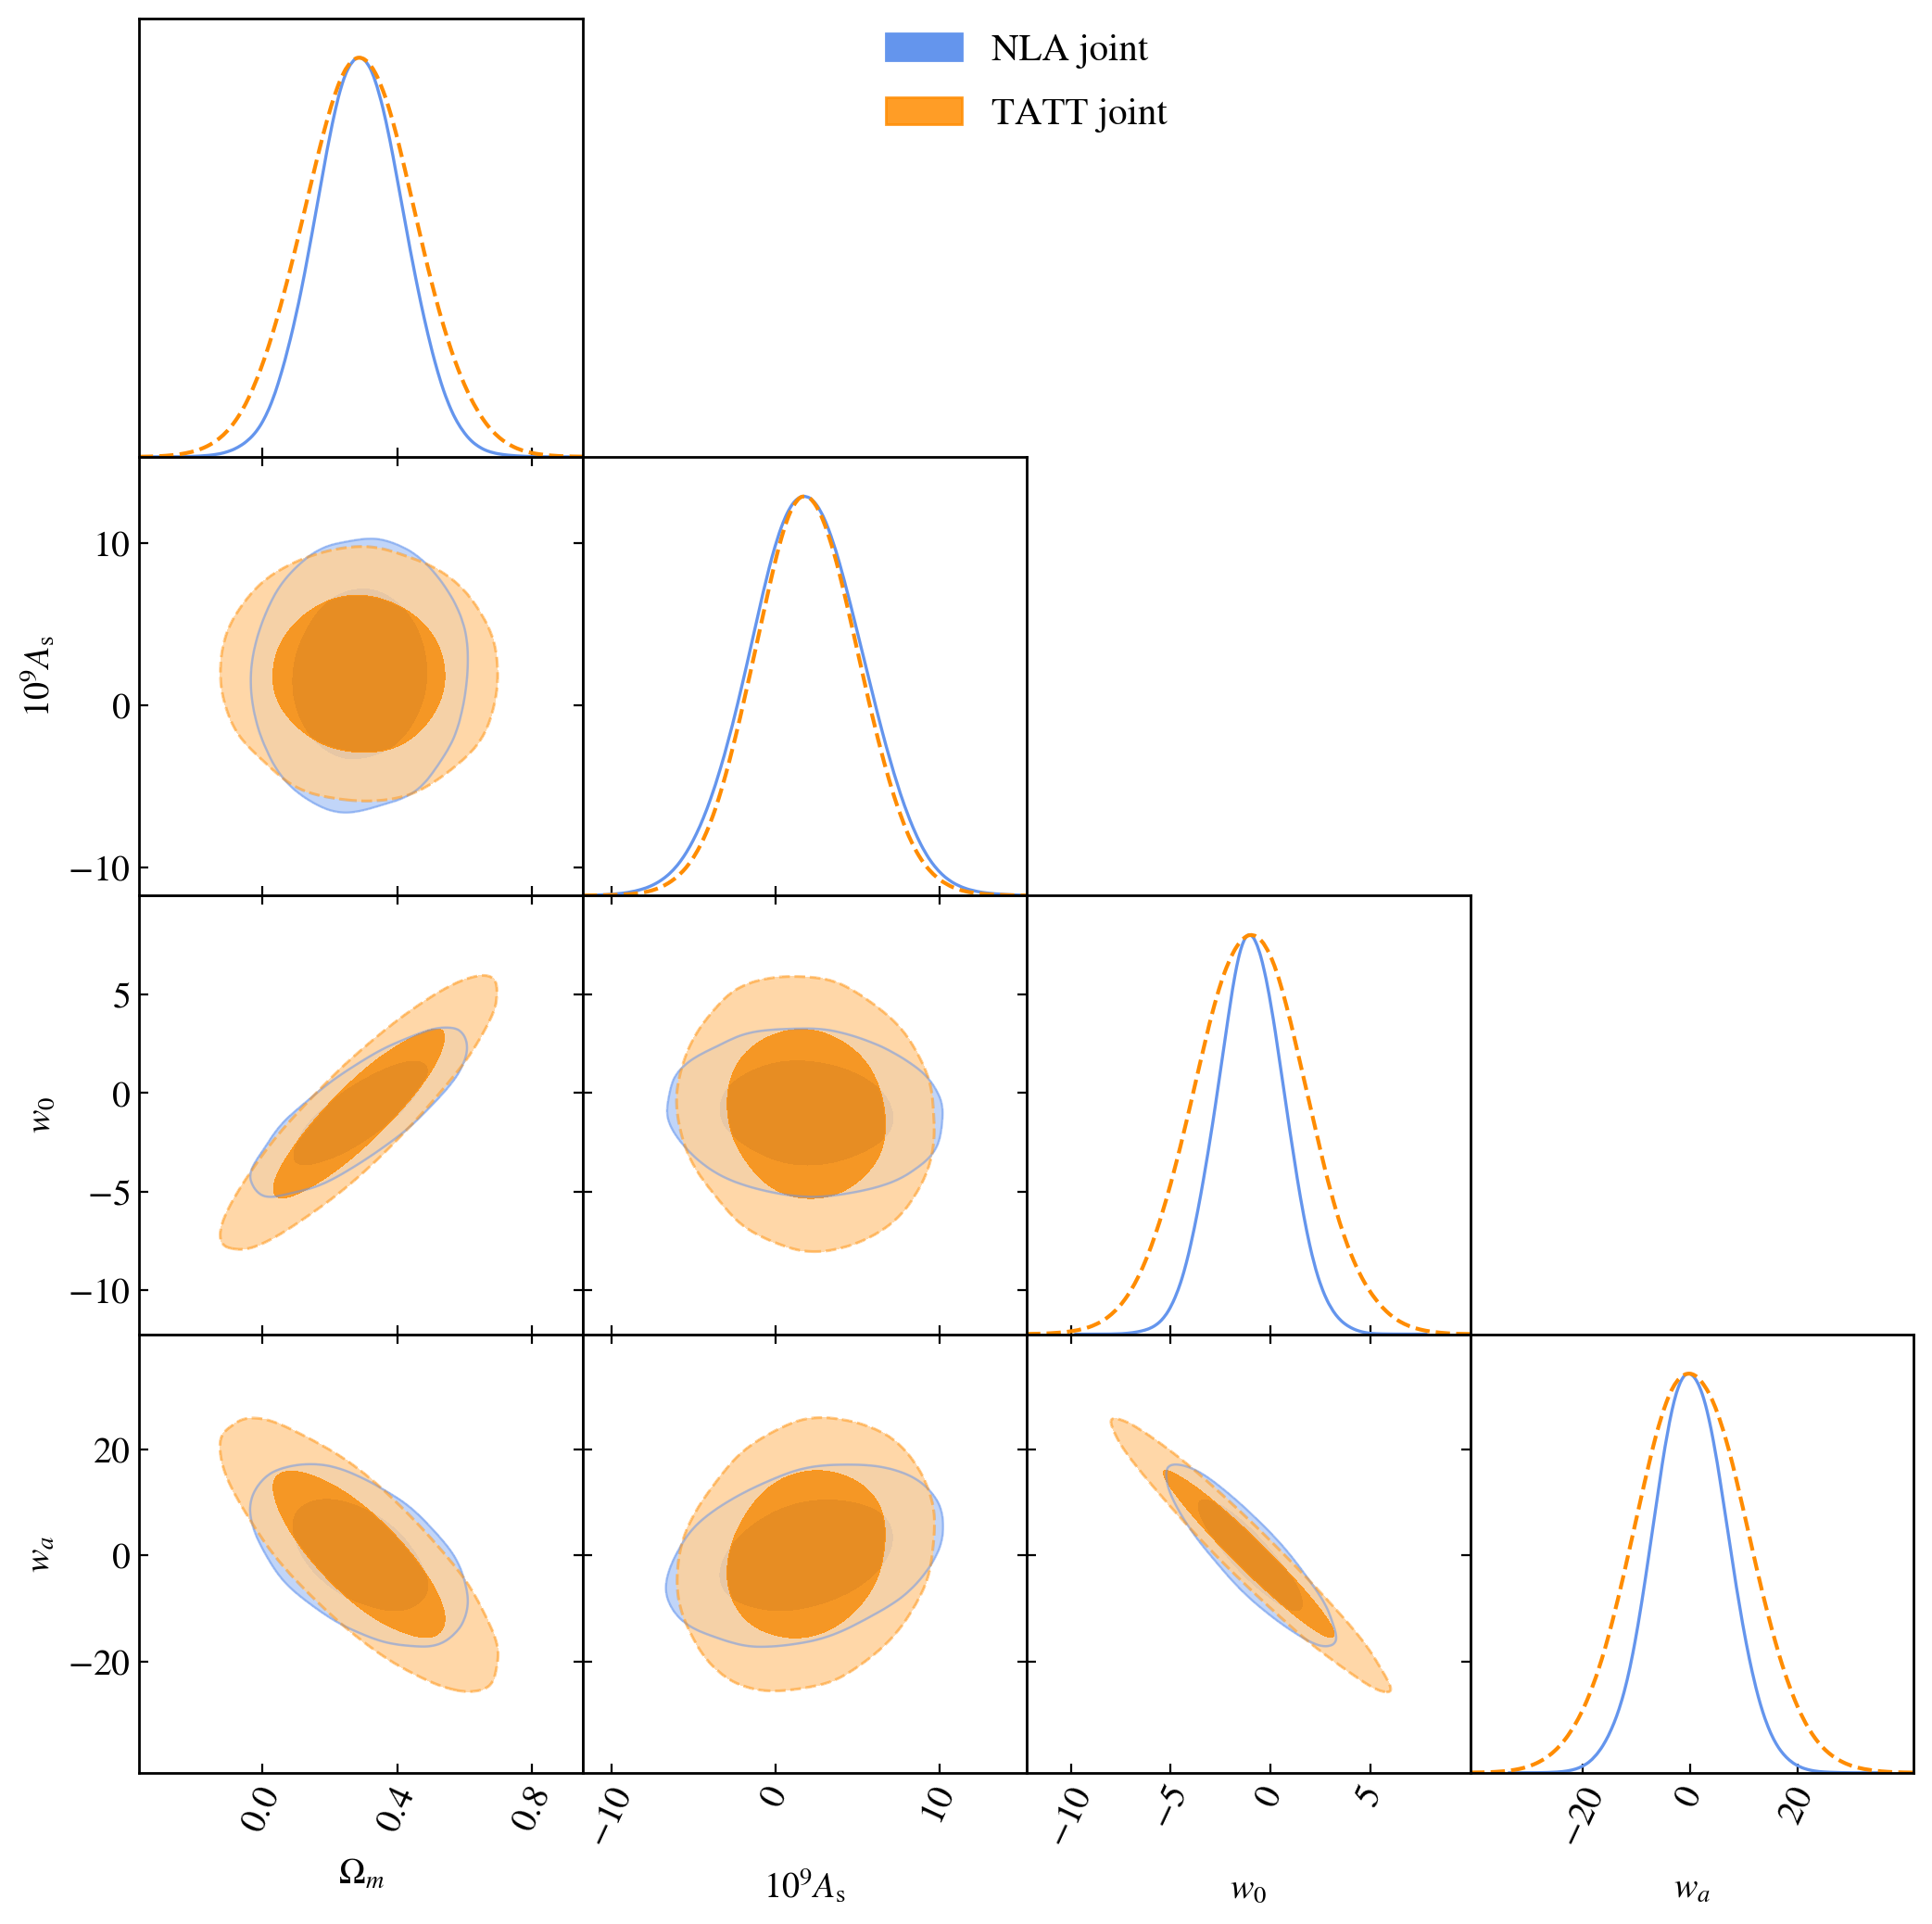

In [11]:
common_names = ["omegam", "As_1e9", "w", "wa"]
common_labels = [r"\Omega_m", r"10^9A_\mathrm{s}", r"w_0", r"w_a"]
common_fishers = []
common_mean = []
for name in common_names:
    common_mean.append(forecasts["nla"]["fiducial"][name])
for ia_model in ("nla", "tatt"):
    forecast = forecasts[ia_model]
    parameter_cov = cnu.parameter_covariance(
        fisher=forecast["information"]["fisher_joint"],
        names=forecast["names"],
    )
    selected = []
    for name in common_names:
        selected.append(forecast["names"].index(name))
    common_covariance = parameter_cov[np.ix_(selected, selected)]
    common_fishers.append(np.linalg.solve(common_covariance, np.eye(len(selected))))
cnu.plot_Fisher(
    F=common_fishers,
    mu=np.asarray(common_mean),
    select=list(range(len(common_names))),
    labels=common_labels,
    names=common_names,
    chain_names=["NLA joint", "TATT joint"],
    filled=True,
)
plt.show()


Numerical convergence requires another full derivative calculation at finer
sampling and a comparison of step sizes. The accuracy notebook shows a cheaper
screen before that expensive confirmation. The sign plots, two-column fits and
full marginalized errors answer different questions; none by itself establishes
agreement with the published measurement, finite-simulation likelihood or posterior.